# Taller 5 — ¿Queja, elogio o ninguno de los dos?
### Clasificar reseñas en tres clases (negativa · neutra · positiva) · enfoque CRISP-DM

**Minería de Datos · 26160 · grupo 020-81 · 2026-3**

| Integrante  |
|---|
| David Zahid Riveros Hernández |
| Juan Pablo Mosquera Marin |
| Oscar Manuel Contreras Gacha |
| Anderson David Arenas Gutierrez  |


## 1 · Comprensión del negocio Parte A


**Objetivo de negocio.** En el comercio existe el cliente que no está ni contento ni bravo 3 estrellas. Es el que todavía se puede recuperar o perder y hoy el sistema solo separa quejas de elogios. Se quiere saber si un modelo puede reconocerlo.

**Objetivo de minería de datos.** Clasificar el texto de una reseña en `negativa` (1-2 ), `neutra` (3 ) o `positiva` (4-5 ), estimar el error con validación cruzada estratificada y medirlo en la prueba **una sola vez**.

**Qué métrica manda: el F1 macro.** Es el promedio sin ponderar del F1 de cada clase, así que la neutra pesa un tercio aunque tenga la mitad de reseñas que las otras. El F1 combina precisión y recall asi que no se puede ganar diciendo neutra a todo ni dejando de decirla nunca.

**Por qué no la exactitud.** Con 20 % de neutras, la exactitud premia ignorarlas: un modelo que **nunca** acierte una neutra puede llegar, como máximo, al 80 % de exactitud. La exactitud se reporta siempre, pero no decide.

**Costo del error — una frase.** Confundir un neutro con un contento es lo más caro, porque el cliente que estaba en riesgo pasa desapercibido y se pierde la oportunidad de recuperarlo asi que confundirlo con un molesto solo cuesta una atención que quizá no hacía falta.

1. **Modelo (Parte B).** Se escoge el líder por F1 macro medio. Si la banda (media ± desviación entre pliegues) de otro modelo se traslapa con la del líder, se declaran **empatados** y desempata el **recall de la neutra**, luego la menor desviación.
2. **Pesos de clase (Parte D).** Manda el F1 macro: si cambia más que el ruido entre pliegues, se sigue su dirección  si cambia menos, desempata el recall de la neutra. La exactitud no decide.
3. **Prueba (Parte E).** No se usa para escoger nada. Se mide una vez con la configuración ya decidida.

## 0 · Preparación técnica

Configuración inmutable, contrato de datos y fábricas de modelos. Esta celda no imprime nada  define las piezas que usan todas las demás.

In [ ]:
import hashlib, json, platform, re, time, warnings
from dataclasses import dataclass
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, make_scorer, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 400)
pd.set_option("display.width", 140)


@dataclass(frozen=True)
class Config:
    """Única fuente de verdad de los parámetros del experimento."""
    seed: int = 42
    k_folds: int = 5
    classes: tuple = ("negativa", "neutra", "positiva")
    train_file: str = "resenas_amazon_es_clase.csv"
    test_file: str = "amazon_es_test.jsonl"
    # TF-IDF de palabras y pares (lo visto en clase)  se guarda como tupla para que el dataclass sea inmutable
    tfidf: tuple = (("ngram_range", (1, 2)), ("min_df", 2), ("sublinear_tf", True))
    expected_train_counts: tuple = (("negativa", 8000), ("neutra", 4000), ("positiva", 8000))
    artifacts_dir: str = "artefactos"

    @property
    def tfidf_params(self) -> dict:
        return dict(self.tfidf)


CFG = Config()
NEUTRA = "neutra"
np.random.seed(CFG.seed)


def find_file(name: str) -> Path:
    """Busca el archivo junto al notebook, en ./data, en Colab o en la carpeta de subidas."""
    for base in [Path("."), Path("data"), Path("datos"), Path("/content"),
                 Path("/content/drive/MyDrive"), Path("/mnt/user-data/uploads")]:
        if (base / name).exists():
            return base / name
    raise FileNotFoundError(f"No encuentro '{name}'. Ponlo junto al notebook o ajusta find_file().")


def stars_to_class(stars: pd.Series) -> pd.Series:
    """1-2 -> negativa · 3 -> neutra · 4-5 -> positiva (definición del taller)."""
    out = np.select([stars.isin([1, 2]), stars.eq(3), stars.isin([4, 5])], list(CFG.classes), default="?")
    assert "?" not in out, "Hay estrellas fuera del rango 1-5"
    return pd.Series(out, index=stars.index, name="clase")


def validate_train(df: pd.DataFrame) -> None:
    """Contrato de datos del entrenamiento: si algo cambia, el notebook falla temprano y con mensaje."""
    assert {"id", "estrellas", "resena"} <= set(df.columns), "Faltan columnas esperadas"
    assert df[["id", "estrellas", "resena"]].notna().all().all(), "Hay nulos"
    assert df["id"].is_unique, "Hay ids repetidos"
    assert df["estrellas"].between(1, 5).all(), "Estrellas fuera de 1-5"
    assert df["resena"].str.strip().str.len().gt(0).all(), "Hay reseñas vacías"
    got = stars_to_class(df["estrellas"]).value_counts().to_dict()
    assert got == dict(CFG.expected_train_counts), f"Conteos por clase distintos a los del enunciado: {got}"


def make_model(name: str, class_weight=None):
    """Fábrica de clasificadores. Todos con semilla fija  NB no admite class_weight."""
    if name == "Naive Bayes":
        if class_weight is not None:
            raise ValueError("MultinomialNB no admite class_weight")
        return MultinomialNB()
    if name == "Regresión logística":
        return LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=CFG.seed)
    if name == "SVM lineal":
        return LinearSVC(max_iter=5000, class_weight=class_weight, random_state=CFG.seed)
    raise KeyError(name)


def build_pipeline(clf) -> Pipeline:
    """TF-IDF + clasificador en un solo objeto: el vocabulario y los IDF se ajustan SOLO con cada pliegue de entrenamiento."""
    return Pipeline([("tfidf", TfidfVectorizer(**CFG.tfidf_params)), ("clf", clf)])


MODEL_NAMES = ["Naive Bayes", "Regresión logística", "SVM lineal"]

SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "recall_neutra": make_scorer(recall_score, labels=[NEUTRA], average="macro", zero_division=0),
    "precision_neutra": make_scorer(precision_score, labels=[NEUTRA], average="macro", zero_division=0),
}


def run_cv(estimator, X, y, cv) -> pd.DataFrame:
    """Validación cruzada estratificada  devuelve una fila por pliegue con todas las métricas."""
    r = cross_validate(estimator, X, y, cv=cv, scoring=SCORING, n_jobs=-1, error_score="raise")
    out = pd.DataFrame({m: r[f"test_{m}"] for m in SCORING})
    out["fit_time"] = r["fit_time"]
    out.index = [f"pliegue {i + 1}" for i in range(len(out))]
    return out


def mean_std(s: pd.Series, d: int = 4) -> str:
    """media ± desviación (muestral, ddof=1, sobre los k pliegues)."""
    return f"{s.mean():.{d}f} ± {s.std(ddof=1):.{d}f}"


def band(s: pd.Series) -> tuple:
    return s.mean() - s.std(ddof=1), s.mean() + s.std(ddof=1)


def bands_overlap(a: pd.Series, b: pd.Series) -> bool:
    (alo, ahi), (blo, bhi) = band(a), band(b)
    return alo <= bhi and blo <= ahi


def wilson(k: int, n: int, z: float = 1.96) -> tuple:
    """Intervalo de Wilson al 95 % para una proporción."""
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - mitad, centro + mitad

## 2 · Comprensión de los datos

Solo se usa el archivo de entrenamiento. **La prueba no se abre hasta la parte E.**

In [2]:
path_train = find_file(CFG.train_file)
df = pd.read_csv(path_train)
validate_train(df)                      # contrato de datos: si falla, se detiene aquí
df["clase"] = stars_to_class(df["estrellas"])
df["n_palabras"] = df["resena"].str.split().str.len()

print(f"Python {platform.python_version()} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · semilla {CFG.seed}")
print(f"Archivo: {path_train.name} · {len(df):,} filas · columnas originales: id, estrellas, resena")
print(f"Nulos: {int(df[['id','estrellas','resena']].isna().sum().sum())} · ids repetidos: {int(df['id'].duplicated().sum())} · textos repetidos: {int(df['resena'].duplicated().sum())}")
print(f"Longitud en palabras → min {df.n_palabras.min()} · mediana {df.n_palabras.median():.0f} · p95 {df.n_palabras.quantile(.95):.0f} · máx {df.n_palabras.max()}")
print("Contrato de datos (validate_train): OK")

Python 3.13.7 · pandas 2.2.3 · scikit-learn 1.7.2 · semilla 42
Archivo: resenas_amazon_es_clase.csv · 20,000 filas · columnas originales: id, estrellas, resena
Nulos: 0 · ids repetidos: 0 · textos repetidos: 0
Longitud en palabras → min 2 · mediana 22 · p95 73 · máx 395
Contrato de datos (validate_train): OK



- Los datos pasan 20 000 reseñas, sin nulos, sin ids ni textos repetidos, y los conteos por clase coinciden con el enunciado. No hay que deduplicar ni imputar nada.

In [3]:
dist = (df.groupby(["clase", "estrellas"]).size().rename("reseñas").reset_index())
dist["% del total"] = (dist["reseñas"] / len(df) * 100).round(1)
display(dist)

por_clase = df["clase"].value_counts().reindex(CFG.classes)
mayoritaria = por_clase.idxmax()
print(f"\nPor clase: {por_clase.to_dict()}")
print(f"Exactitud de un modelo que siempre dice "{mayoritaria}": {por_clase.max() / len(df):.3f}")
print(f"Exactitud máxima de un modelo que NUNCA reconoce una neutra y acierta todo lo demás: {1 - por_clase[NEUTRA] / len(df):.3f}")

,clase,estrellas,reseñas,% del total
0,negativa,1,4000,20.0
1,negativa,2,4000,20.0
2,neutra,3,4000,20.0
3,positiva,4,4000,20.0
4,positiva,5,4000,20.0



Por clase: {'negativa': 8000, 'neutra': 4000, 'positiva': 8000}
Exactitud de un modelo que siempre dice «negativa»: 0.400
Exactitud máxima de un modelo que NUNCA reconoce una neutra y acierta todo lo demás: 0.800


**Lectura.**
- Cada estrella tiene exactamente 4 000 reseñas (20 %). El desbalance lo crea la agrupación, negativa 40 %, neutra 20 %, positiva 40 %.
- decir siempre negativa da 0.400 de exactitud, y un modelo que nunca reconozca una neutra tiene un techo de 0.800.
- con esta distribución, la exactitud sola no puede decir si se está reconociendo al cliente neutro.

,count,25%,50%,75%,max
clase,,,,,
negativa,8000,15,23,37,288
neutra,4000,14,23,36,335
positiva,8000,10,20,31,395


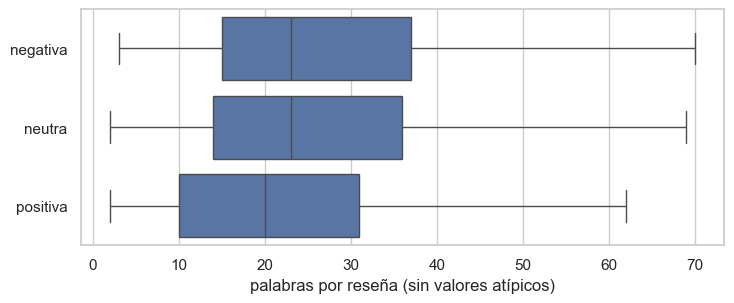

In [ ]:
resumen = (df.groupby("clase")["n_palabras"].describe(percentiles=[.25, .5, .75])
             .loc[list(CFG.classes), ["count", "25%", "50%", "75%", "max"]].round(0).astype(int))
display(resumen)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
sns.boxplot(data=df, x="n_palabras", y="clase", order=list(CFG.classes), showfliers=False, ax=ax)
ax.set_xlabel("palabras por reseña (sin valores atípicos)")  ax.set_ylabel("")
plt.tight_layout()  plt.show()

**Lectura.**
- Las medianas son prácticamente iguales (23, 23 y 20 palabras) y los cuartiles también. La longitud no distingue a la neutra  las positivas son algo más cortas.
- Se descarta la longitud como pista

In [ ]:
muestra = df.groupby("clase", group_keys=False).sample(3, random_state=CFG.seed).sort_values("clase")
for _, r in muestra.iterrows():
    txt = r["resena"] if len(r["resena"]) <= 260 else r["resena"][:260] + "…"
    print(f"[{r['clase']:<8} · {r['estrellas']} ] {txt}\n")

[negativa · 2★] Estas sartenes tienen buen aspecto, pero se pega la comida y agarra en pocos días, no me las volvería a comprar nunca. Cualquier otra sartén barata dura mas tiempo sin que comience a pegarse la comida a los pocos días de uso, no aguantan nada, están para tirar…

[negativa · 2★] Las cortinas son una porquería, la primera vez que se han lavado se han perdido los dibujos y eso que no usé lejía. La calidad es malísima y el color se va solo con ducharte.

[negativa · 2★] Pésima calidad, en dos usos ya se ha deformado

[neutra   · 3★] Queda demasiado justa y aprieta un poco de mas, pero si no la llevas justa se va a ir moviendo mucho durante la actividad física.

[neutra   · 3★] PARA EL CORTE DE QUESOS DUROS, NO SIRVE YA QUE SE DOBLA LA CUCHILLA

[neutra   · 3★] Se rompen con cierta facilidad. También estaría mejor si pensarán algo más. En días de viento se mueven fácilmente. Pero al precio que estaba y para lo que lp necesitaba, cumplieron su objetivo.

[positiva · 5★] Un pa

**Lectura.**
- La frontera entre clases es difusa. Hay positivas con queja , negativas que empiezan elogiando y una neutra que lee como queja pura.
- La estrella resume el ánimo no necesariamente el contenido del texto. una hipotesis para la parte c es que una parte del error de la neutra será ruido de etiqueta, no un fallo del modelo.

## 3 · Preparación de los datos

| Decisión | Razón |
|---|---|
| Etiqueta: 1-2  → negativa, 3  → neutra, 4-5  → positiva | Definición del enunciado (`stars_to_class`). La prueba trae `label` 0-4 y se convierte con la misma función. |
| `X` es el **texto crudo**  el TF-IDF va dentro del `Pipeline` | Así el vocabulario y los IDF se calculan solo con el pliegue de entrenamiento. Ajustarlos fuera deja que la validación influya en el vocabulario (fuga  −0.8 en la rúbrica). Una celda lo verifica con `assert`. |
| Sin limpieza manual, sin quitar *stopwords* | "no", "pero", "sin", "muy" son justo las palabras que separan la neutra de las otras. Quitarlas destruiría señal. |
| TF-IDF de palabras y pares (`ngram_range=(1, 2)`), `min_df=2`, `sublinear_tf=True` | Lo visto en clase. `min_df=2` descarta términos que aparecen una sola vez (no se pueden generalizar)  `sublinear_tf` amortigua las repeticiones. |
| Sin deduplicación | No hay textos repetidos en el entrenamiento (sección 2). |
| `StratifiedKFold(5, shuffle=True, seed=42)`, **el mismo objeto para todos** | Mantiene 20 % de neutras en cada pliegue y hace que las comparaciones entre modelos sean **pareadas**. |
| Hiperparámetros por defecto, sin ajustar | Ajustarlos exige validación cruzada anidada  queda declarado como límite (sección 8). |

In [6]:
X = df["resena"]            # texto crudo: toda transformación vive dentro del Pipeline
y = df["clase"]
cv = StratifiedKFold(n_splits=CFG.k_folds, shuffle=True, random_state=CFG.seed)   # los mismos pliegues para TODOS los modelos

# Verificación anti-fuga: el primer paso de todo modelo debe ser el TF-IDF, dentro del Pipeline
for nombre in MODEL_NAMES:
    assert isinstance(build_pipeline(make_model(nombre)).steps[0][1], TfidfVectorizer)

## 4 · Modelado — Parte B: tres modelos

**Diseño.** Tres clasificadores sobre el mismo `Pipeline` (TF-IDF → modelo), los mismos 5 pliegues estratificados y las mismas métricas: **exactitud y F1 macro como media ± desviación** (desviación muestral, `ddof=1`, entre los 5 pliegues). Se añaden el recall y la precisión de la neutra (guardia de la Parte A), el tiempo de ajuste y **dos referencias sin aprendizaje** (azar proporcional y "siempre la mayoritaria") para saber qué significa un número.

La regla de selección es la de la sección 1  el código de más abajo la implementa tal cual.

In [7]:
resultados = {}
t0 = time.time()
for nombre in MODEL_NAMES:
    resultados[nombre] = run_cv(build_pipeline(make_model(nombre)), X, y, cv)
resultados["(referencia) azar proporcional"] = run_cv(
    build_pipeline(DummyClassifier(strategy="stratified", random_state=CFG.seed)), X, y, cv)
resultados["(referencia) siempre la mayoritaria"] = run_cv(
    build_pipeline(DummyClassifier(strategy="most_frequent")), X, y, cv)

tabla_b = pd.DataFrame({
    nombre: {
        "Exactitud": mean_std(r["accuracy"]),
        "F1 macro": mean_std(r["f1_macro"]),
        "Recall neutra": mean_std(r["recall_neutra"]),
        "Precisión neutra": mean_std(r["precision_neutra"]),
        "Ajuste por pliegue (s)": f"{r['fit_time'].mean():.1f}",
    } for nombre, r in resultados.items()
}).T
print(f"Validación cruzada estratificada k={CFG.k_folds} · {len(X):,} reseñas · media ± desviación entre pliegues · {time.time() - t0:.0f} s\n")
display(tabla_b)

Validación cruzada estratificada k=5 · 20,000 reseñas · media ± desviación entre pliegues · 21 s



,Exactitud,F1 macro,Recall neutra,Precisión neutra,Ajuste por pliegue (s)
Naive Bayes,0.6984 ± 0.0030,0.5187 ± 0.0016,0.0022 ± 0.0016,0.5000 ± 0.3536,1.1
Regresión logística,0.7116 ± 0.0036,0.6137 ± 0.0025,0.1935 ± 0.0042,0.4271 ± 0.0169,3.7
SVM lineal,0.6981 ± 0.0047,0.6153 ± 0.0044,0.2372 ± 0.0101,0.3836 ± 0.0113,1.2
(referencia) azar proporcional,0.3590 ± 0.0072,0.3336 ± 0.0080,0.2068 ± 0.0145,0.2050 ± 0.0144,1.1
(referencia) siempre la mayoritaria,0.4000 ± 0.0000,0.1905 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9


**Lectura.**
- **Referencias.** El azar proporcional da F1 macro 0.334 y recall de neutra 0.207. "Siempre la mayoritaria" da 0.400 de exactitud pero F1 macro de 0.190: la exactitud engaña.
- **Naive Bayes.** Su exactitud (0.698) parece competitiva, pero el F1 macro es 0.519 y el **recall de la neutra es 0.002**: casi nunca dice "neutra". Su precisión de neutra (0.500 ± 0.354) es puro ruido: en varios pliegues apenas emitió predicciones de esa clase. Es el caso de manual de una clase que la exactitud esconde.
- **Regresión logística.** La mayor exactitud (0.712), F1 macro 0.614 y recall de neutra 0.194, **indistinguible del azar** (0.207 ± 0.015): sin pesos casi no encuentra neutros.
- **SVM lineal.** F1 macro 0.615 ± 0.004, recall de neutra 0.237 (algo por encima del azar) y precisión de 0.384.
- Los tres se ajustan en pocos segundos por pliegue (menos de 2 s aquí): el costo computacional no es criterio de decisión.
- **Idea central.** Ordenar por exactitud da LR > NB ≈ SVM  ordenar por F1 macro da SVM ≈ LR ≫ NB. La métrica cambia la desicion del modelo.

In [8]:
f1 = {n: resultados[n]["f1_macro"] for n in MODEL_NAMES}
ac = {n: resultados[n]["accuracy"] for n in MODEL_NAMES}

filas = []
for i, a in enumerate(MODEL_NAMES):
    for b in MODEL_NAMES[i + 1:]:
        d = f1[a] - f1[b]                                           # diferencia por pliegue (mismos pliegues → pareada)
        k, n_te, n_tr = CFG.k_folds, len(X) / CFG.k_folds, len(X) * (1 - 1 / CFG.k_folds)
        t = d.mean() / np.sqrt((1 / k + n_te / n_tr) * d.var(ddof=1))     # t corregida (Nadeau & Bengio, 2003)
        filas.append({
            "A": a, "B": b,
            "banda F1 de A": "[%.4f, %.4f]" % band(f1[a]),
            "banda F1 de B": "[%.4f, %.4f]" % band(f1[b]),
            "¿traslapan (F1)?": "sí" if bands_overlap(f1[a], f1[b]) else "no",
            "¿traslapan (exactitud)?": "sí" if bands_overlap(ac[a], ac[b]) else "no",
            "Δ F1 medio (A−B)": round(d.mean(), 4),
            "pliegues donde A > B": f"{int((d > 0).sum())}/{k}",
            "p (t corregida)": round(2 * stats.t.sf(abs(t), k - 1), 4),
        })
display(pd.DataFrame(filas))
print("\nF1 macro por pliegue:")
display(pd.DataFrame(f1).round(4))

,A,B,banda F1 de A,banda F1 de B,¿traslapan (F1)?,¿traslapan (exactitud)?,Δ F1 medio (A−B),pliegues donde A > B,p (t corregida)
0,Naive Bayes,Regresión logística,"[0.5171, 0.5204]","[0.6112, 0.6162]",no,no,-0.0950,0/5,0.0000
1,Naive Bayes,SVM lineal,"[0.5171, 0.5204]","[0.6109, 0.6198]",no,sí,-0.0966,0/5,0.0000
2,Regresión logística,SVM lineal,"[0.6112, 0.6162]","[0.6109, 0.6198]",sí,no,-0.0016,2/5,0.4848



F1 macro por pliegue:


,Naive Bayes,Regresión logística,SVM lineal
pliegue 1,0.5175,0.6115,0.6139
pliegue 2,0.5181,0.6165,0.6159
pliegue 3,0.5181,0.6122,0.6100
pliegue 4,0.5216,0.6163,0.6222
pliegue 5,0.5184,0.6120,0.6147


**Lectura — B.2.**
- **Naive Bayes vs regresión logística** Las bandas de F1 macro, [0.5171, 0.5204] y [0.6112, 0.6162] no se traslapan, y tampoco las de exactitud. LR gana en los 5 pliegues, con una diferencia de 0.095 (p < 0.0001). Naive Bayes queda descartado.
- **Regresión logística vs SVM lineal.** Las bandas de F1 macro **sí se traslapan** ([0.6112, 0.6162] y [0.6109, 0.6198]). La diferencia media es 0.0016, SVM gana en 3 de 5 pliegues y p = 0.48 con la t corregida. No hay evidencia de que difieran en la métrica que manda. Con 5 pliegues la prueba es orientativa, pero la conclusión es la misma que dicen las bandas.
- En exactitud sí hay diferencia (LR 0.712 vs SVM 0.698, sin traslape), pero en recall de neutra gana SVM (0.237 vs 0.194). Por la regla de la sección 1 manda el F1 macro y, al haber empate, desempata el recall de la neutra.
- Naive Bayes y SVM sí se traslapan en exactitud (0.698 contra 0.698). Mirando solo la exactitud no se podría distinguir un modelo que ignora la neutra de uno que la busca.

In [9]:
def seleccionar_modelo(res: dict) -> dict:
    """líder por F1 macro si hay empate de bandas,
    desempata el recall de la neutra y después la menor desviación."""
    f1m = {n: res[n]["f1_macro"] for n in MODEL_NAMES}
    lider = max(MODEL_NAMES, key=lambda n: f1m[n].mean())
    empatados = [n for n in MODEL_NAMES if n == lider or bands_overlap(f1m[n], f1m[lider])]
    if len(empatados) == 1:
        return {"modelo": lider, "empatados": empatados, "motivo": "líder en F1 macro, sin traslape de bandas con ningún otro"}
    elegido = max(empatados, key=lambda n: (round(res[n]["recall_neutra"].mean(), 4), -f1m[n].std(ddof=1)))
    return {"modelo": elegido, "empatados": empatados,
            "motivo": "bandas de F1 macro traslapadas entre los empatados → desempata el recall de la neutra"}


decision = seleccionar_modelo(resultados)
CHOSEN = decision["modelo"]
print(f"Líder por F1 macro medio: {max(MODEL_NAMES, key=lambda n: resultados[n]['f1_macro'].mean())}")
print(f"Modelos empatados con el líder: {decision['empatados']}")
print(f"→ Modelo escogido: {CHOSEN}  ({decision['motivo']})")
r = resultados[CHOSEN]
print(f"   exactitud {mean_std(r['accuracy'])} · F1 macro {mean_std(r['f1_macro'])} · recall neutra {mean_std(r['recall_neutra'])}")

Líder por F1 macro medio: SVM lineal
Modelos empatados con el líder: ['Regresión logística', 'SVM lineal']
→ Modelo escogido: SVM lineal  (bandas de F1 macro traslapadas entre los empatados → desempata el recall de la neutra)
   exactitud 0.6981 ± 0.0047 · F1 macro 0.6153 ± 0.0044 · recall neutra 0.2372 ± 0.0101


**Lectura — decisión.** Se queda la **SVM lineal**.
- es la líder por F1 macro medio (0.6153), pero su banda se traslapa con la de la regresión logística, así que ambas quedan empatadas y desempata el recall de la neutra (0.237 contra 0.194), que es la métrica de respaldo fijada en la Parte A.
- **Lo que no se hizo:** escoger por exactitud (habría ganado la regresión logística) ni mirar la prueba.
- **Costo asumido:** la SVM lineal no entrega probabilidades calibradas, solo márgenes. Para este taller no hace falta, y en la sección 7 el margen se usa como señal de confianza.

## 5 · Evaluación

Todo lo que sigue usa predicciones **fuera de pliegue** (`cross_val_predict`) sobre el entrenamiento: cada reseña la predice un modelo que no la vio. **La prueba sigue cerrada.**

*Nota metodológica.* Las predicciones agrupadas vienen de cinco modelos distintos, así que las métricas agrupadas se parecen a la media por pliegue, pero no son idénticas.

### Parte C — Dónde se equivoca

In [10]:
pipe_c = build_pipeline(make_model(CHOSEN))
y_cv = cross_val_predict(pipe_c, X, y, cv=cv, n_jobs=-1)       # predicción fuera de muestra para cada reseña de ENTRENAMIENTO

print(f"Modelo: {CHOSEN} · predicciones fuera de pliegue sobre el entrenamiento ({len(y_cv):,} reseñas), sin tocar la prueba\n")
print(classification_report(y, y_cv, labels=list(CFG.classes), digits=3))
rep = classification_report(y, y_cv, labels=list(CFG.classes), output_dict=True)
peor = min(CFG.classes, key=lambda c: rep[c]["f1-score"])
print(f"Clase con menor F1: {peor} (F1 {rep[peor]['f1-score']:.3f}) · con menor recall: {min(CFG.classes, key=lambda c: rep[c]['recall'])}")

Modelo: SVM lineal · predicciones fuera de pliegue sobre el entrenamiento (20,000 reseñas), sin tocar la prueba

              precision    recall  f1-score   support

    negativa      0.724     0.811     0.765      8000
      neutra      0.383     0.237     0.293      4000
    positiva      0.763     0.815     0.788      8000

    accuracy                          0.698     20000
   macro avg      0.623     0.621     0.615     20000
weighted avg      0.671     0.698     0.680     20000

Clase con menor F1: neutra (F1 0.293) · con menor recall: neutra


**Lectura — C.1 (reporte por clase).**
- La **neutra es la peor detectada, por mucho**: F1 0.293 (precisión 0.383, recall 0.237). Negativa y positiva rondan 0.77-0.79 de F1, casi 50 puntos más.
- En lenguaje de negocio: de cada 100 neutros reales el modelo encuentra 24, y de cada 100 que marca como neutros solo 38 lo son.
- La exactitud (0.698) y el promedio ponderado (0.680) se ven bien porque las clases grandes los arrastran  el F1 macro (0.615) deja ver la brecha.

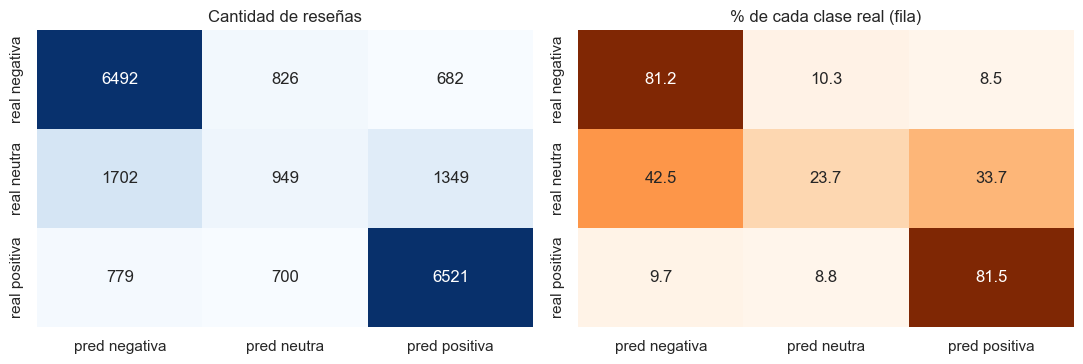

De 4,000 neutras reales:
  → predichas como negativa : 1,702  (42.5%)
  → predichas como neutra   :   949  (23.7%)
  → predichas como positiva : 1,349  (33.7%)

Cuando el modelo dice «neutra», ¿quién era en realidad?
  real negativa :   826  (33.4%)
  real neutra   :   949  (38.3%)
  real positiva :   700  (28.3%)


In [ ]:
cm = pd.DataFrame(confusion_matrix(y, y_cv, labels=list(CFG.classes)),
                  index=[f"real {c}" for c in CFG.classes], columns=[f"pred {c}" for c in CFG.classes])
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])  axes[0].set_title("Cantidad de reseñas")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Oranges", cbar=False, ax=axes[1])  axes[1].set_title("% de cada clase real (fila)")
plt.tight_layout()  plt.show()

n_neu = cm.loc[f"real {NEUTRA}"].sum()
print(f"De {n_neu:,} neutras reales:")
for c in CFG.classes:
    v = cm.loc[f"real {NEUTRA}", f"pred {c}"]
    print(f"  → predichas como {c:<9}: {v:>5,}  ({v / n_neu:.1%})")
print("\nCuando el modelo dice "neutra", ¿quién era en realidad?")
col = cm[f"pred {NEUTRA}"]
for idx, v in col.items():
    print(f"  {idx:<14}: {v:>5,}  ({v / col.sum():.1%})")

**Lectura — C.1 (matriz de confusión).**
- De las **4 000 neutras reales**: 949 (23.7 %) se reconocen  **1 702 (42.5 %) se van a negativa** y **1 349 (33.7 %) a positiva**. La neutra se reparte entre sus dos vecinas, algo más hacia la negativa: no hay un único sesgo.
- Por columnas, cuando el modelo dice "neutra" (2 475 veces) solo 949 (38.3 %) lo son  826 eran negativas y 700 positivas.
- Con el costo de la Parte A: el error caro (neutro tomado por contento) afecta a **1 349 clientes (33.7 %)**  el barato (tomado por molesto), a 1 702 (42.5 %).

In [ ]:
df_cv = df.assign(pred=y_cv)
mal_neutras = df_cv[(df_cv["clase"] == NEUTRA) & (df_cv["pred"] != NEUTRA)]
print(f"Neutras mal clasificadas en la validación cruzada: {len(mal_neutras):,} de {int((df_cv['clase'] == NEUTRA).sum()):,}")
print("Se leen 10 al azar (semilla fija, sin escoger a mano)  n.  = posición dentro de la muestra.\n")
lectura10 = mal_neutras.sample(10, random_state=CFG.seed)
for i, (_, r) in enumerate(lectura10.iterrows(), 1):
    txt = r["resena"] if len(r["resena"]) <= 420 else r["resena"][:420] + "…"
    print(f"{i:>2}. [{r['id']} · {r['estrellas']}  · predicha: {r['pred']}] {txt}\n")

Neutras mal clasificadas en la validación cruzada: 3,051 de 4,000
Se leen 10 al azar (semilla fija, sin escoger a mano); n.º = posición dentro de la muestra.

 1. [es_0408514 · 3★ · predicha: negativa] Lo cogí con ganas, soy gran fan de GIRLS, pero conforme avanzas, hay historias que sobran, muchas de relleno y otras con las que te partes. Eso sí es como anecdótico, porque no es un tipo de libro que llegue a la patata o que te haga pensar mucho, no tiene mensaje, más bien muchos contradictorios y distantes entre sí. Lo recomiendo si tienes mucho tiempo y no esperas nada.

 2. [es_0160825 · 3★ · predicha: negativa] La verdad que se hace super incomodo doblar la goma cada vez que quiero abrir mis airpods ... pensaba que iría articulado y no ... los he devuelto

 3. [es_0732125 · 3★ · predicha: negativa] No lo he probado aun, por qué no vienen las instrucciones en castellano en algún sitio se pueden conseguir?

 4. [es_0225712 · 3★ · predicha: negativa] Su utilidad u capacidad de carga y 

**Lectura — C.2 (diez neutras mal clasificadas, leídas una por una).** De 4 000 neutras, 3 051 (76 %) se clasificaron mal  esta es una muestra al azar de ellas.
- **Posible ruido de etiqueta en  2, 5 y 10** ("los he devuelto", "No me ha gustado que fuera tan pequeño", "me la esperaba más grande"). Son quejas puntuales y que leen como negativas aun para una persona  creemos que el 3  vino del tono moderado del autor, no del texto. Aquí el modelo se equivoca menos de lo que parece.
- **Pros y contras en equilibrio en 1, 6 y 7.** La n. 1 mezcla elogios con "no tiene mensaje" y "historias que sobran" la n. 6 dice "tardó muchísimo" pero "por el precio está muy bien… funciona bien"  la n.  7, "muy fácil de poner" pero "no cubre toda la superficie". suma palabras y se queda con el bando que tiene más palabras fuertes sin saber cuál pesa más.
- **"Bien" regular en 8 y 9** ("Está bien, cumple su cometido", "Producto está bien. Fuerte lo bastante para su utilidad"). La neutralidad está en el tono, pero léxicamente son iguales a una 4  suave  nada las separa de las positivas.
- **Sin opinión sobre el producto en 3 y 4** (una pregunta por las instrucciones, "no lo he probado"  una frase suelta sobre el ruido). No hay sentimiento que leer: el modelo cae en negativa por el "no" y por palabras de defecto ("ruidosa").
- **Resumen:** 3 de ruido de etiqueta, 3 de equilibrio, 2 de "bien" regular y 2 sin opinión. Son diez casos (anecdóticos)  la celda siguiente comprueba si el patrón se sostiene en las 4 000.

In [13]:
CONTRASTE = r"\b(?:pero|aunque|sin embargo|no obstante|eso sí|salvo|excepto|aun así|por contra)\b"
ATENUADOR = r"\b(?:regular|normal|correcto|aceptable|cumple|justo|sin más|ni fu ni fa|podría ser mejor|no está mal|por el precio|calidad[- ]precio|esperaba más)\b"

df_cv["grupo"] = np.select(
    [(df_cv.clase == NEUTRA) & (df_cv.pred == NEUTRA),
     (df_cv.clase == NEUTRA) & (df_cv.pred == "negativa"),
     (df_cv.clase == NEUTRA) & (df_cv.pred == "positiva")],
    ["neutra bien clasificada", "neutra → predicha negativa", "neutra → predicha positiva"], default="otra")
neu = df_cv[df_cv.grupo != "otra"].copy()
low = neu["resena"].str.lower()
neu["tiene contraste (pero, aunque…)"] = low.str.contains(CONTRASTE, regex=True)
neu["tiene atenuador (regular, cumple…)"] = low.str.contains(ATENUADOR, regex=True)
neu["menos de 12 palabras"] = neu["n_palabras"] < 12

cols = ["tiene contraste (pero, aunque…)", "tiene atenuador (regular, cumple…)", "menos de 12 palabras"]
tabla_err = neu.groupby("grupo")[cols].mean().mul(100).round(1)
tabla_err.insert(0, "reseñas", neu.groupby("grupo").size())
tabla_err["palabras (mediana)"] = neu.groupby("grupo")["n_palabras"].median()
display(tabla_err.loc[["neutra bien clasificada", "neutra → predicha negativa", "neutra → predicha positiva"]])
print("(porcentaje de reseñas del grupo que cumplen cada condición)")

,reseñas,"tiene contraste (pero, aunque…)","tiene atenuador (regular, cumple…)",menos de 12 palabras,palabras (mediana)
grupo,,,,,
neutra bien clasificada,949,68.2,21.2,18.3,23.0
neutra → predicha negativa,1702,44.6,11.3,18.9,23.0
neutra → predicha positiva,1349,43.9,18.8,23.7,22.0


(porcentaje de reseñas del grupo que cumplen cada condición)


**Lectura — C.2 comprobación sobre las 4 000 neutras.** 
- **Contraste ("pero", "aunque"…).** Lo tienen el 68.2 % de las neutras acertadas, contra 44.6 % de las enviadas a negativa y 43.9 % de las enviadas a positiva. El modelo acierta la neutra cuando se declara explícitamente "por un lado… por otro" y falla cuando no. Pero casi la mitad de los errores también tiene contraste: son los casos de 1, 6 y 7.
- **"regular", "cumple", "no está mal".** 21.2 % en las acertadas, 11.3 % en las enviadas a negativa y 18.8 % en las enviadas a positiva. Sin palabras suaves el texto parece queja  con ellas, se confunde con un elogio, porque cumple también aparece en las 4.
- **Longitud.** La mediana es 22-23 palabras en los tres grupos, igual que en la sección 2: no explica nada. Solo el grupo enviado a positiva tiene algo más de textos cortos

In [ ]:
modelo_full = build_pipeline(make_model(CHOSEN)).fit(X, y)            # solo entrenamiento  se usa para interpretar, no para evaluar
tf, clf = modelo_full.named_steps["tfidf"], modelo_full.named_steps["clf"]
if hasattr(clf, "coef_"):
    terms = np.array(tf.get_feature_names_out())
    top = {}
    for i, c in enumerate(clf.classes_):
        top[c] = list(terms[np.argsort(clf.coef_[i])[::-1][:15]])
    display(pd.DataFrame(top, index=range(1, 16)))
else:
    print("El modelo escogido no expone coeficientes  se omite esta vista.")

# ¿Los autores escriben su propia calificación en el texto?
menciona = df["resena"].str.lower().str.contains(r"\b(?:[1-5]|una|dos|tres|cuatro|cinco)\s+estrellas?\b", regex=True)
print("\nReseñas que mencionan su propia calificación ("tres estrellas", "2 estrellas"…), por clase real:")
print((menciona.groupby(df["clase"]).agg(["sum", "mean"]).rename(columns={"sum": "reseñas", "mean": "proporción"})
       .loc[list(CFG.classes)].round(4)))

,negativa,neutra,positiva
1,no,pero,perfecto
2,mala,producto pero,genial
3,no cumple,tres estrellas,perfectamente
4,dos estrellas,aunque,excelente
5,no funciona,esperaba que,perfecta
6,fatal,lo bueno,encantado
7,no encaja,precio está,buena
8,imposible,gruesa,perfectas
9,muy mal,se empezó,muy recomendable
10,no recomiendo,lluvia,encantada



Reseñas que mencionan su propia calificación («tres estrellas», «2 estrellas»…), por clase real:
          reseñas  proporción
clase                        
negativa      106      0.0132
neutra         76      0.0190
positiva      117      0.0146


**Lectura.**
- Las clases extremas: negativa ("no", "mala", "no cumple", "no funciona", "fatal", "devolver") y positiva ("perfecto", "genial", "excelente", "encantado", "muy recomendable").
- La neutra no: sus términos son de contraste y expectativa "pero", "producto pero", "aunque", "esperaba que", "lo bueno", "precio está". Se define por la estructura de la frase, no por palabras emocionales, y por eso es la clase más difícil.
- También aparecen términos sin sentido evidente ("gruesa", "lluvia", "se empezó", "el plastico"): son coeficientes apoyados en pocas reseñas, el costo de usar pares de palabras en 20 000 documentos.
- Solo 1.3-1.9 % de las reseñas de cada clase mencionan su propia calificación "tres estrellas", "2 estrellas"  asoma en los términos "tres estrellas", "dos estrellas", pero no explica el rendimiento.

### Parte D — Pesar las clases

`class_weight="balanced"` multiplica la penalización de cada error por `n / (k · n_clase)`: con 20 000 reseñas y 3 clases, la neutra pesa **1.67** y las otras dos **0.83**. Se compara contra la misma configuración sin pesos, con los mismos pliegues. (Naive Bayes no admite `class_weight`  el modelo escogido sí, y un `assert` lo verifica.)

In [15]:
CW_OK = CHOSEN != "Naive Bayes"
assert CW_OK, "El modelo escogido no admite class_weight  habría que justificar otra alternativa en la parte D"

res_plain = resultados[CHOSEN]
res_bal = run_cv(build_pipeline(make_model(CHOSEN, class_weight="balanced")), X, y, cv)

metricas = {"accuracy": "Exactitud", "f1_macro": "F1 macro", "recall_neutra": "Recall neutra", "precision_neutra": "Precisión neutra"}
comp = pd.DataFrame({
    "sin pesos": {v: mean_std(res_plain[k]) for k, v in metricas.items()},
    "class_weight='balanced'": {v: mean_std(res_bal[k]) for k, v in metricas.items()},
    "Δ medio": {v: f"{res_bal[k].mean() - res_plain[k].mean():+.4f}" for k, v in metricas.items()},
    "pliegues que mejoran": {v: f"{int((res_bal[k] > res_plain[k]).sum())}/{CFG.k_folds}" for k, v in metricas.items()},
})
print(f"Modelo: {CHOSEN} · mismos pliegues · media ± desviación\n")
display(comp)

Modelo: SVM lineal · mismos pliegues · media ± desviación



,sin pesos,class_weight='balanced',Δ medio,pliegues que mejoran
Exactitud,0.6981 ± 0.0047,0.6904 ± 0.0039,-0.0078,0/5
F1 macro,0.6153 ± 0.0044,0.6242 ± 0.0043,+0.0089,5/5
Recall neutra,0.2372 ± 0.0101,0.3025 ± 0.0112,+0.0653,5/5
Precisión neutra,0.3836 ± 0.0113,0.3674 ± 0.0112,-0.0162,0/5


**Lectura — D.1.**
- **Recall de la neutra: 0.237 → 0.303 (+0.065)**, y mejora en los 5 pliegues.
- **F1 macro: 0.615 → 0.624 (+0.009)**, también en los 5 pliegues.
- **Exactitud: 0.698 → 0.690 (−0.008)**, y no mejora en ningún pliegue.
- La precisión de la neutra baja de 0.384 a 0.367: el recall se paga con precisión, porque el modelo marca más cosas como neutras y algunas son falsas.
- El cambio es pequeño pero **consistente**: ningún pliegue lo contradice.

In [16]:
y_bal = cross_val_predict(build_pipeline(make_model(CHOSEN, class_weight="balanced")), X, y, cv=cv, n_jobs=-1)
r0 = pd.DataFrame(classification_report(y, y_cv, labels=list(CFG.classes), output_dict=True)).T.loc[list(CFG.classes)]
r1 = pd.DataFrame(classification_report(y, y_bal, labels=list(CFG.classes), output_dict=True)).T.loc[list(CFG.classes)]
por_clase_cmp = pd.concat({"sin pesos": r0[["precision", "recall", "f1-score"]],
                           "balanced": r1[["precision", "recall", "f1-score"]]}, axis=1).round(3)
display(por_clase_cmp)

cm_b = pd.DataFrame(confusion_matrix(y, y_bal, labels=list(CFG.classes)), index=list(CFG.classes), columns=list(CFG.classes))
print("\nMatriz de confusión con class_weight='balanced' (filas = real, columnas = predicha):")
display(cm_b)
n_neu = int((y == NEUTRA).sum())
a, b = cm.loc[f"real {NEUTRA}", f"pred {NEUTRA}"], cm_b.loc[NEUTRA, NEUTRA]
print(f"\nNeutras reconocidas: {a:,} → {b:,} de {n_neu:,} ({a / n_neu:.1%} → {b / n_neu:.1%})")
for c in ("negativa", "positiva"):
    print(f"Neutras tomadas por {c}: {cm.loc[f'real {NEUTRA}', f'pred {c}']:,} → {cm_b.loc[NEUTRA, c]:,}")

sin pesos                  balanced                
         precision recall f1-score precision recall f1-score
negativa     0.724  0.812    0.765     0.733  0.782    0.757
neutra       0.383  0.237    0.293     0.367  0.302    0.332
positiva     0.763  0.815    0.788     0.776  0.793    0.784


Matriz de confusión con class_weight='balanced' (filas = real, columnas = predicha):


,negativa,neutra,positiva
negativa,6256,1137,607
neutra,1567,1210,1223
positiva,711,948,6341



Neutras reconocidas: 949 → 1,210 de 4,000 (23.7% → 30.2%)
Neutras tomadas por negativa: 1,702 → 1,567
Neutras tomadas por positiva: 1,349 → 1,223


**Lectura — D.1 (por clase y en la matriz).**
- Neutra: F1 0.293 → 0.332, recall 0.237 → 0.302. Negativa: recall 0.812 → 0.782. Positiva: recall 0.815 → 0.793.
- Se reconocen **261 neutras más** (949 → 1 210): 135 menos se van a negativa y 126 menos a positiva. A cambio, las clases grandes pierden unas 400 reseñas bien clasificadas, y de ahí sale la caída neta de exactitud (unas 155 reseñas de 20 000).
- Sigue siendo flojo 7 de cada 10 neutras siguen sin reconocerse y el error caro neutro a contento baja solo de 1 349 a 1 223. Pesar las clases mueve el umbral de decisión, pero no crea la información que el texto no trae.

In [ ]:
def decidir_pesos(plain: pd.DataFrame, bal: pd.DataFrame) -> tuple:
    """Regla fijada en la sección 1: el F1 macro manda  si su cambio no supera el ruido entre pliegues, decide el recall de la neutra."""
    d_f1 = bal["f1_macro"].mean() - plain["f1_macro"].mean()
    d_rec = bal["recall_neutra"].mean() - plain["recall_neutra"].mean()
    ruido = max(plain["f1_macro"].std(ddof=1), bal["f1_macro"].std(ddof=1))
    if d_f1 > ruido:
        return True, f"el F1 macro sube {d_f1:+.4f}, más que el ruido entre pliegues ({ruido:.4f})"
    if d_f1 < -ruido:
        return False, f"el F1 macro baja {d_f1:+.4f}, más que el ruido entre pliegues ({ruido:.4f})"
    return d_rec > 0, (f"el F1 macro cambia {d_f1:+.4f}, dentro del ruido ({ruido:.4f})  "
                       f"desempata el recall de la neutra ({d_rec:+.4f})")


USE_BALANCED, motivo_w = decidir_pesos(res_plain, res_bal)
CLASS_WEIGHT = "balanced" if USE_BALANCED else None
exac_d = res_bal["accuracy"].mean() - res_plain["accuracy"].mean()
f1_d = res_bal["f1_macro"].mean() - res_plain["f1_macro"].mean()
print(f"Exactitud: {exac_d:+.4f} · F1 macro: {f1_d:+.4f} → {'MISMA dirección' if exac_d * f1_d > 0 else 'direcciones DISTINTAS'}")
print(f"Decisión: class_weight = {CLASS_WEIGHT!r}  ({motivo_w})")
print(f"Configuración final: {CHOSEN} + TF-IDF {CFG.tfidf_params} + class_weight={CLASS_WEIGHT!r}")

Exactitud: -0.0078 · F1 macro: +0.0089 → direcciones DISTINTAS
Decisión: class_weight = 'balanced'  (el F1 macro sube +0.0089, más que el ruido entre pliegues (0.0044))
Configuración final: SVM lineal + TF-IDF {'ngram_range': (1, 2), 'min_df': 2, 'sublinear_tf': True} + class_weight='balanced'


**Lectura — D.2.** La exactitud (−0.0078) y el F1 macro (+0.0089) se mueven en **direcciones distintas**. **Nos quedamos con el F1 macro**, por lo escrito en la Parte A:
- La exactitud premia a las clases grandes, y la pregunta del taller es sobre la neutra.
- El cambio del F1 macro (+0.0089) supera el ruido entre pliegues (0.0044) y se repite en 5 de 5, así que la regla se activa por magnitud, no por desempate.
- **Costo asumido:** 0.8 puntos de exactitud unas 155 reseñas de 20 000 y 1.6 puntos de precisión de la neutra.

**Configuración final:** SVM lineal + TF-IDF (`min_df=2`, `sublinear_tf`) + `class_weight='balanced'`.

## 6 · Evaluación final — Parte E: la prueba, una sola vez

**Protocolo.** Todo está decidido (modelo, TF-IDF y pesos) con la validación cruzada. La celda siguiente: (1) abre la prueba **por primera vez** y valida su contrato  (2) cuenta ids y textos compartidos con el entrenamiento (solo higiene, sin métricas)  (3) ajusta el modelo final con **todo** el entrenamiento  (4) predice **una vez** detrás de `OneShotGate`  (5) reporta y cierra con la frase de negocio. `label` 0-4 se convierte a 1-5 estrellas y luego a clase.

In [18]:
class OneShotGate:
    """Guarda contra el error más caro del taller: medir sobre la prueba más de una vez (y terminar escogiendo con ella)."""
    def __init__(self):
        self._used = False

    def __call__(self, fn, *args, **kwargs):
        if self._used:
            raise RuntimeError("La prueba ya se midió una vez en esta sesión  no se vuelve a tocar.")
        self._used = True
        return fn(*args, **kwargs)


TEST_GATE = OneShotGate()

# --- 1) carga y contrato de datos de la prueba (primera vez que se abre el archivo) ---
path_test = find_file(CFG.test_file)
te = pd.read_json(path_test, lines=True)
assert {"id", "text", "label"} <= set(te.columns) and te["label"].isin(range(5)).all() and te[["text", "label"]].notna().all().all()
te["estrellas"] = te["label"] + 1                       # label 0-4  →  1-5 estrellas
te["clase"] = stars_to_class(te["estrellas"])
X_te, y_te = te["text"], te["clase"]

# --- 2) higiene: ¿la prueba comparte ids o textos con el entrenamiento? (solo conteo  no se mide nada) ---
norm = lambda s: s.str.strip().str.lower()
ids_comunes = len(set(te["id"]) & set(df["id"]))
textos_comunes = len(set(norm(te["text"])) & set(norm(df["resena"])))

# --- 3) ajuste final con TODO el entrenamiento y configuración ya decidida ---
final = build_pipeline(make_model(CHOSEN, class_weight=CLASS_WEIGHT)).fit(X, y)

# --- 4) UNA sola predicción sobre la prueba ---
y_te_pred = TEST_GATE(final.predict, X_te)

acc_te = accuracy_score(y_te, y_te_pred)
f1_te = f1_score(y_te, y_te_pred, average="macro")
cm_te = pd.DataFrame(confusion_matrix(y_te, y_te_pred, labels=list(CFG.classes)),
                     index=[f"real {c}" for c in CFG.classes], columns=[f"pred {c}" for c in CFG.classes])
n_neu_te = int(cm_te.loc[f"real {NEUTRA}"].sum())
rec_neu_te = cm_te.loc[f"real {NEUTRA}", f"pred {NEUTRA}"] / n_neu_te
lo, hi = wilson(int(cm_te.loc[f"real {NEUTRA}", f"pred {NEUTRA}"]), n_neu_te)

print(f"Prueba: {len(te):,} reseñas · distribución {y_te.value_counts().reindex(CFG.classes).to_dict()}")
print(f"Ids compartidos con el entrenamiento: {ids_comunes} · textos idénticos (normalizados): {textos_comunes}")
print(f"Configuración: {CHOSEN} · class_weight={CLASS_WEIGHT!r} · TF-IDF {CFG.tfidf_params}\n")
print(classification_report(y_te, y_te_pred, labels=list(CFG.classes), digits=3))
display(cm_te)

rv = resultados[CHOSEN] if CLASS_WEIGHT is None else res_bal
print(f"\nExactitud  prueba {acc_te:.4f} · validación cruzada {mean_std(rv['accuracy'])}")
print(f"F1 macro   prueba {f1_te:.4f} · validación cruzada {mean_std(rv['f1_macro'])}")
print(f"Recall neutra en prueba: {rec_neu_te:.1%}  (intervalo del 95 %: {lo:.1%} – {hi:.1%}, n = {n_neu_te:,})")
print("\nFrase de negocio con los números de la prueba:")
print(f""De cada 100 clientes neutros, el modelo reconoce {rec_neu_te * 100:.0f} como neutros  "
      f"{cm_te.loc[f'real {NEUTRA}', f'pred positiva'] / n_neu_te * 100:.0f} los toma por contentos y "
      f"{cm_te.loc[f'real {NEUTRA}', f'pred negativa'] / n_neu_te * 100:.0f} por molestos."")

Prueba: 5,000 reseñas · distribución {'negativa': 2000, 'neutra': 1000, 'positiva': 2000}
Ids compartidos con el entrenamiento: 0 · textos idénticos (normalizados): 8
Configuración: SVM lineal · class_weight='balanced' · TF-IDF {'ngram_range': (1, 2), 'min_df': 2, 'sublinear_tf': True}

              precision    recall  f1-score   support

    negativa      0.748     0.804     0.775      2000
      neutra      0.384     0.329     0.355      1000
    positiva      0.792     0.789     0.791      2000

    accuracy                          0.703      5000
   macro avg      0.641     0.641     0.640      5000
weighted avg      0.693     0.703     0.697      5000



,pred negativa,pred neutra,pred positiva
real negativa,1608,274,118
real neutra,374,329,297
real positiva,168,253,1579



Exactitud  prueba 0.7032 · validación cruzada 0.6904 ± 0.0039
F1 macro   prueba 0.6401 · validación cruzada 0.6242 ± 0.0043
Recall neutra en prueba: 32.9%  (intervalo del 95 %: 30.1% – 35.9%, n = 1,000)

Frase de negocio con los números de la prueba:
«De cada 100 clientes neutros, el modelo reconoce 33 como neutros; 30 los toma por contentos y 37 por molestos.»


**Lectura — Parte E.**
- **Resultado en la prueba** (5 000 reseñas, 2 000 / 1 000 / 2 000, la misma proporción del entrenamiento): exactitud **0.703**, F1 macro **0.640**. Para la neutra, precisión 0.384, recall 0.329 y F1 0.355.
- **Coherencia con la validación cruzada.** La prueba sale algo mejor: exactitud 0.703 contra 0.690 ± 0.004 y F1 macro 0.640 contra 0.624 ± 0.004. Una explicación plausible es que el modelo final se ajusta con 20 000 reseñas y no con 16 000  los 8 textos idénticos entre ambos archivos (0.16 % de la prueba) no mueven nada. No se tomó ninguna decisión con la prueba: aunque hubiera salido peor, la configuración no habría cambiado.
- **Neutras:** recall 32.9 % (intervalo del 95 %: 30.1 %–35.9 %), en línea con el 30.2 % de la validación cruzada. De 1 000 neutros reales, 329 se reconocen, 374 se toman por molestos y 297 por contentos.
- el intervalo mide el azar del muestreo de 1 000 neutros, no el ruido de la etiqueta de 3 estrellas.

 **De cada 100 clientes neutros, el modelo reconoce 33 como neutros  a 30 los confunde con clientes contentos y a 37 con clientes molestos.**

Dicho al revés de cada 100 clientes que el modelo marca como neutros, 38 lo son (329 de 856), casi el doble que elegir al azar 20 %. El modelo sirve para priorizar una lista de seguimiento, no para decidir de forma automática.